# The movie graph: a quick start

Movies, the people who made them, and the companies that produced and distributed them, as one network. Build it first, from
the data folder:

```bash
cd data/raw && mkdir -p features/graph && duckdb < ../../scripts/network/graph_tables.sql
../../.venv/bin/python ../../scripts/network/resolve_companies.py
../../.venv/bin/python ../../scripts/network/build_graph.py
```

That writes `nodes.csv`, `edges.csv` and `movie_graph.graphml` to `data/raw/features/graph/`. The docstring of
`scripts/network/build_graph.py` lists every field. This notebook loads the graph, describes it, and shows
three ways in: one-mode projections, a collaborator network, and a leakage-safe cast measure tested against
profit.

In [1]:
from collections import Counter, defaultdict
from itertools import combinations
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy import stats

G = Path("../data/raw/features/graph")
SEED = 1
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

nodes = pd.read_csv(G / "nodes.csv", dtype={"id": str}, low_memory=False).set_index("id")
edges = pd.read_csv(G / "edges.csv", dtype={"source": str, "target": str})
print(nodes.type.value_counts().to_string())
print(f"\n{len(edges):,} edges")
print(edges.role.value_counts().to_string())

type
person     90605
movie      12673
company     6594

280,087 edges
role
actor              123332
writer              31319
producer            31213
studio              20403
editor              16360
distributor         15677
composer            14581
director            14035
cinematographer     13167


## Loading it as a graph

`nodes.csv` and `edges.csv` are the plain version; `movie_graph.graphml` is the same graph for networkx
(`nx.read_graphml`, about a minute) or igraph. Here the graph is built from the tables, as an undirected
bipartite graph: people, studios and distributors on one side, movies on the other. Multiple roles collapse
into one edge with a `roles` list.

In [2]:
B = nx.Graph()
B.add_nodes_from((i, {"type": t}) for i, t in nodes.type.items())
for (s, t), grp in edges.groupby(["source", "target"]):
    B.add_edge(s, t, roles=sorted(set(grp.role)), year=grp.year.iloc[0])
deg = pd.Series(dict(B.degree()))
print(f"{B.number_of_nodes():,} nodes, {B.number_of_edges():,} edges, "
      f"{nx.number_connected_components(B):,} components; largest has "
      f"{len(max(nx.connected_components(B), key=len)):,} nodes")

109,872 nodes, 263,178 edges, 39 components; largest has 109,360 nodes


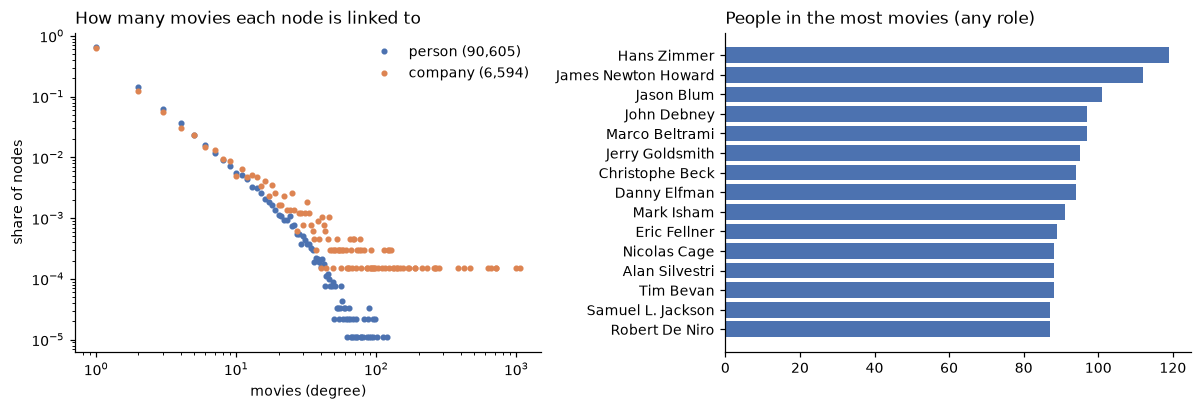

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for t, c in (("person", "#4c72b0"), ("company", "#dd8452")):
    k = deg[nodes.index[nodes.type == t]]
    vals, counts = np.unique(k, return_counts=True)
    axes[0].loglog(vals, counts / counts.sum(), "o", ms=3, color=c, label=f"{t} ({len(k):,})")
axes[0].set_xlabel("movies (degree)"); axes[0].set_ylabel("share of nodes")
axes[0].set_title("How many movies each node is linked to", loc="left"); axes[0].legend(frameon=False)
top = deg[nodes.index[nodes.type == "person"]].sort_values().tail(15)
axes[1].barh([nodes.label[i] for i in top.index], top.values, color="#4c72b0")
axes[1].set_title("People in the most movies (any role)", loc="left")
plt.tight_layout(); plt.show()

## Companies

Studios and distributors are one node type, `company`. `scripts/network/resolve_companies.py` gives each
infobox name a Wikidata ID, and names share a node only when they share an ID: through the Wikipedia article
the name links to, a redirect the target company itself lists as one of its names, or the film's own
Wikidata entry. Labels and subsidiaries stay apart from their parents, and names with no ID stay as written.
`data/company_ids.csv` lists every name with the ID it got and why, for checking or overriding.

6,594 companies: 2,867 with a Wikidata ID, 3,727 known only by name; 229 carry more than one name


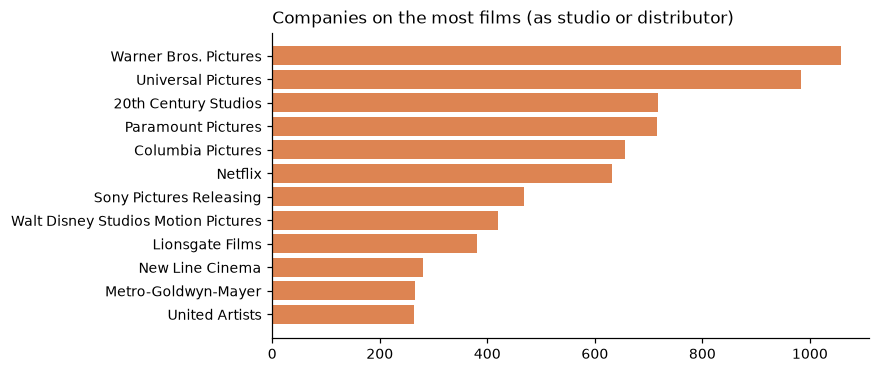

,label,qid,names,films
id,,,,
company:Q8016302,Warner Bros. Pictures,Q8016302,Warner Bros Pictures|Warner Bros. Pictures,1057
company:Q168383,Universal Pictures,Q168383,"Universal Pictures|Universal Pictures Company,...",984
company:Q434841,20th Century Studios,Q434841,20th Century Fox|20th Century Studios,718
company:Q186941,Columbia Pictures,Q186941,Columbia Pictures|Columbia Pictures Corporation,656
company:Q1323594,Walt Disney Studios Motion Pictures,Q1323594,Buena Vista Distribution|Buena Vista Distribut...,420
company:Q79202,New Line Cinema,Q79202,New Line Cinema|New Line Productions,281
company:Q179200,Metro-Goldwyn-Mayer,Q179200,Metro-Goldwyn Mayer|Metro-Goldwyn-Mayer,265
company:Q219400,United Artists,Q219400,United Artists|United Artists Corporation,264
company:Q465449,Miramax,Q465449,Miramax|Miramax Films,229


In [4]:
comp = nodes[nodes.type == "company"]
films_by_company = edges[edges.role.isin(["studio", "distributor"])].groupby("source").target.nunique()
merged = comp[comp.names.fillna("").str.contains("[|]", regex=True)]
print(f"{len(comp):,} companies: {comp.qid.notna().sum():,} with a Wikidata ID, {comp.qid.isna().sum():,} known only by name; "
      f"{len(merged):,} carry more than one name")
top = films_by_company.loc[comp.index].sort_values().tail(12)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh([nodes.label[i] for i in top.index], top.values, color="#dd8452")
ax.set_title("Companies on the most films (as studio or distributor)", loc="left")
plt.show()
merged.assign(films=films_by_company.reindex(merged.index)).sort_values("films", ascending=False)[["label", "qid", "names", "films"]].head(15)

## One-mode projections

Most questions are about one kind of node. Two projections cover most of them:

- **actors**, linked when they share a film in which both are billed in the top five;
- **movies**, linked when they share a director, writer or top-five actor (a film's "crew overlap").

Both are restricted here to the clean sample, the films with a usable budget and gross.

In [5]:
clean = set(nodes.index[(nodes.type == "movie") & (nodes.clean == 1)])
cast = edges[(edges.role == "actor") & (edges.ordering <= 5) & edges.target.isin(clean)]

A = nx.Graph()
for movie, grp in cast.groupby("target"):
    for a, b in combinations(sorted(grp.source), 2):
        if A.has_edge(a, b):
            A[a][b]["weight"] += 1
        else:
            A.add_edge(a, b, weight=1)
giant = A.subgraph(max(nx.connected_components(A), key=len)).copy()
print(f"actor projection: {A.number_of_nodes():,} actors, {A.number_of_edges():,} links; "
      f"giant component {giant.number_of_nodes():,} actors")

key = edges[edges.target.isin(clean) & (edges.role.isin(["director", "writer"])
            | ((edges.role == "actor") & (edges.ordering <= 5)))]
M = nx.Graph()
for person, grp in key.groupby("source"):
    for a, b in combinations(sorted(set(grp.target)), 2):
        M.add_edge(a, b, weight=M[a][b]["weight"] + 1 if M.has_edge(a, b) else 1)
print(f"movie projection: {M.number_of_nodes():,} movies, {M.number_of_edges():,} links")

actor projection: 12,353 actors, 62,027 links; giant component 11,230 actors


movie projection: 6,756 movies, 191,343 links


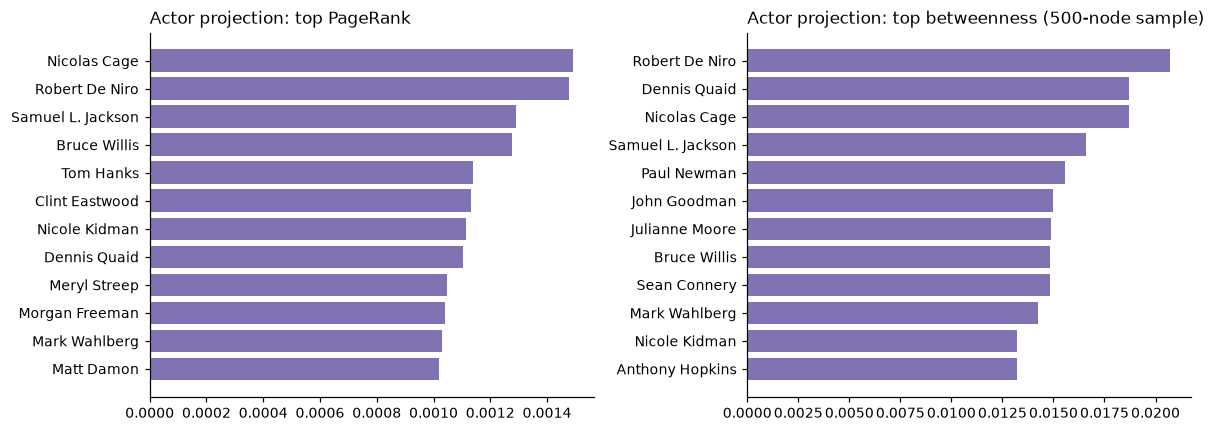

In [6]:
pr = pd.Series(nx.pagerank(giant, weight="weight"))
bt = pd.Series(nx.betweenness_centrality(giant, k=500, seed=SEED, weight=None))
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, s, title in ((axes[0], pr, "PageRank"), (axes[1], bt, "betweenness (500-node sample)")):
    top = s.sort_values().tail(12)
    ax.barh([nodes.label[i] for i in top.index], top.values, color="#8172b2")
    ax.set_title(f"Actor projection: top {title}", loc="left")
plt.tight_layout(); plt.show()

## A collaborator network

The films one person worked on in any role, and the people who appear in at least two of them (top-four
billed actors and crew), coloured by role. Change `WHO` to any `nm` ID in `nodes.csv`.

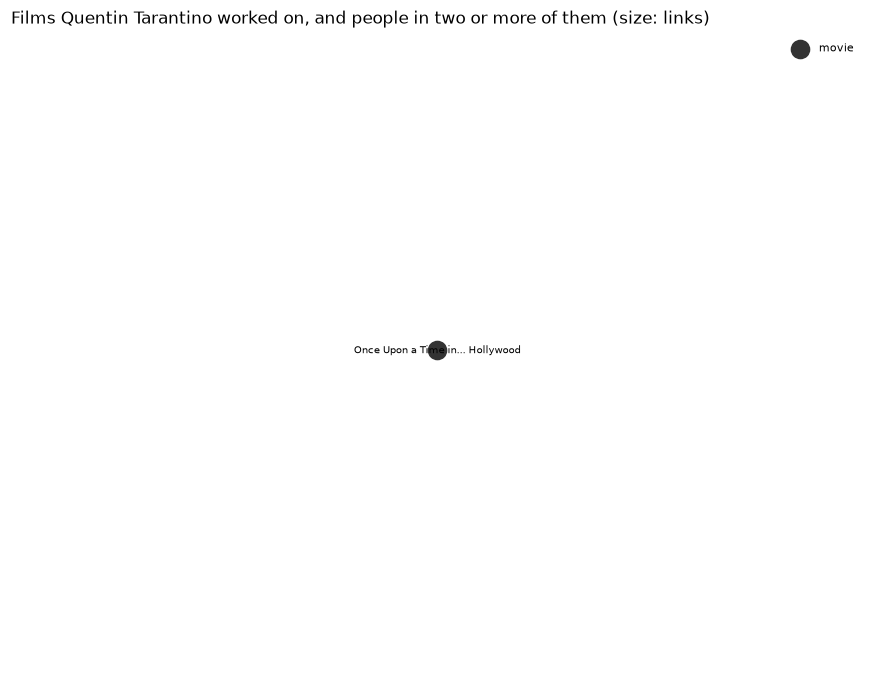

In [7]:
WHO = nodes.index[(nodes.label == "Quentin Tarantino")][0]
films = set(edges.target[edges.source == WHO])
around = edges[edges.target.isin(films) & (edges.source != WHO)
               & ((edges.role != "actor") | (edges.ordering <= 4))
               & ~edges.role.isin(["studio", "distributor"])]
around = around[around.groupby("source").target.transform("nunique") >= 2]  # people in 2+ of these films
E = nx.Graph()
for f in films:
    E.add_node(f, kind="movie")
for _, r in around.iterrows():
    E.add_node(r.source, kind=r.role); E.add_edge(r.source, r.target)
colours = {"movie": "#333333", "actor": "#4c72b0", "director": "#c44e52", "writer": "#dd8452",
           "producer": "#55a868", "composer": "#8172b2", "cinematographer": "#937860", "editor": "#da8bc3"}
pos = nx.spring_layout(E, seed=SEED, k=0.35)
fig, ax = plt.subplots(figsize=(10, 7.5))
nx.draw_networkx_edges(E, pos, ax=ax, alpha=0.25, width=0.6)
for kind, c in colours.items():
    ns = [n for n, k in E.nodes(data="kind") if k == kind]
    nx.draw_networkx_nodes(E, pos, nodelist=ns, ax=ax, node_color=c, node_size=[140 if kind == "movie" else 25 + 15 * E.degree(n) for n in ns], label=kind)
labels = {n: nodes.label[n] for n in E if E.nodes[n]["kind"] == "movie" or E.degree(n) >= 3}
nx.draw_networkx_labels(E, pos, labels, ax=ax, font_size=6.5)
ax.legend(frameon=False, fontsize=7, loc="upper right"); ax.axis("off")
ax.set_title(f"Films {nodes.label[WHO]} worked on, and people in two or more of them (size: links)", loc="left")
plt.show()

## A leakage-safe cast measure

Success makes actors central, so a cast measure that uses a film's own result, or later films, would leak
the outcome into the predictor. Here each clean film's cast experience is computed only from films released
**before** it: the mean number of earlier films (in the 10,000+ vote set) of its top three billed actors.
Then it's compared with the film's gross multiple, with budget and year held fixed.

6,804 clean films | cast's prior films vs ln(multiple): rho -0.162 raw, -0.085 net of budget and year (p = 2.5e-12)


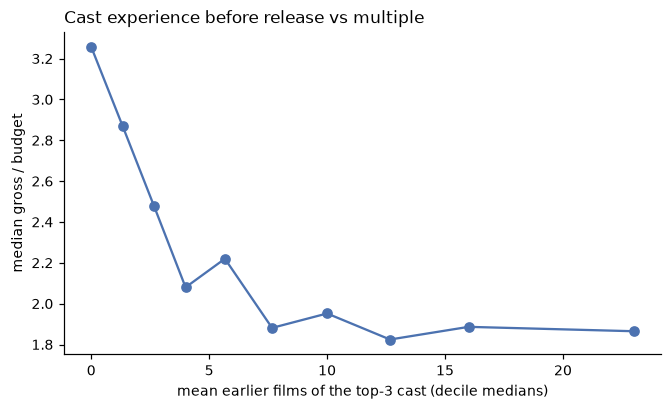

In [8]:
act = edges[(edges.role == "actor")].merge(nodes[["year"]], left_on="target", right_index=True, suffixes=("", "_m"))
first = act.groupby("source").year.apply(sorted).to_dict()
import bisect
def prior_films(person, y):
    return bisect.bisect_left(first.get(person, []), y)
top3 = edges[(edges.role == "actor") & (edges.ordering <= 3) & edges.target.isin(clean)]
exp = top3.assign(prior=[prior_films(p, y) for p, y in zip(top3.source, top3.year)]).groupby("target").prior.mean()
cm = nodes.loc[list(clean), ["year", "budget_usd", "multiple"]].join(exp.rename("cast_prior_films")).dropna()
cm["log_mult"], cm["log_budget"] = np.log(cm.multiple), np.log(cm.budget_usd)

def rank_partial(y, x, z):
    r = stats.rankdata
    Z = np.column_stack([np.ones(len(y))] + [r(c) for c in z.T])
    res = lambda v: r(v) - Z @ np.linalg.lstsq(Z, r(v), rcond=None)[0]
    return stats.pearsonr(res(x), res(y))
rho_raw = stats.spearmanr(cm.cast_prior_films, cm.log_mult)[0]
rho, p = rank_partial(cm.log_mult.values, cm.cast_prior_films.values, cm[["log_budget", "year"]].values)
print(f"{len(cm):,} clean films | cast's prior films vs ln(multiple): rho {rho_raw:+.3f} raw, "
      f"{rho:+.3f} net of budget and year (p = {p:.2g})")

fig, ax = plt.subplots(figsize=(7, 3.8))
bins = pd.qcut(cm.cast_prior_films.rank(method="first"), 10, labels=False)
g = cm.groupby(bins)
ax.plot(g.cast_prior_films.median(), np.exp(g.log_mult.median()), "o-", color="#4c72b0")
ax.set_xlabel("mean earlier films of the top-3 cast (decile medians)"); ax.set_ylabel("median gross / budget")
ax.set_title("Cast experience before release vs multiple", loc="left")
plt.show()

## What the graph says about profit

The question for the project: does who made a film predict how much it returns? Every measure below uses
only films released **before** the film in question (an earlier calendar year), so a film's own success
can't leak into its predictor. Films from 1980 on are used, since earlier films have little history inside
a 10,000+ vote set.

For each film and each group (studio, producers, writers, director, top-three billed cast):

- **track record**: the mean ln(gross / budget) of the group's earlier clean films (needs at least two);
- **experience**: the mean number of earlier films in the graph, in any role;
- **re-teaming**: the share of the top-three cast who acted in an earlier film by the same director.

In [9]:
import bisect, re
from sklearn.linear_model import RidgeCV
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cm = nodes[(nodes.type == "movie") & (nodes.clean == 1)].copy()
cm["log_mult"], cm["log_budget"] = np.log(cm.multiple), np.log(cm.budget_usd)
lm, yr = cm.log_mult.to_dict(), nodes.year.to_dict()

def group(role, ordering):
    if role == "actor":
        return "cast" if ordering <= 3 else None
    return role if role in ("director", "writer", "producer", "studio") else None
edges["grp"] = [group(r, o) for r, o in zip(edges.role, edges.ordering)]

hist_all, hist_clean = defaultdict(list), defaultdict(list)
for s, t in zip(edges.source, edges.target):
    y = yr.get(t)
    if y is None or np.isnan(y):
        continue
    hist_all[s].append(y)
    if t in lm:
        hist_clean[s].append((y, lm[t]))
for v in hist_all.values():
    v.sort()
for v in hist_clean.values():
    v.sort()
clean_years = {k: [y for y, _ in v] for k, v in hist_clean.items()}

def experience(e, y):
    return bisect.bisect_left(hist_all.get(e, []), y)
def track(e, y):
    i = bisect.bisect_left(clean_years.get(e, []), y)
    return [m for _, m in hist_clean.get(e, [])[:i]]

dir_films, act_films = defaultdict(set), defaultdict(set)
for s, t, r in zip(edges.source, edges.target, edges.role):
    if r == "director":
        dir_films[s].add(t)
    elif r == "actor":
        act_films[s].add(t)

feat = defaultdict(dict)
E = edges.dropna(subset=["grp"])
for t, grp in E[E.target.isin(cm.index)].groupby("target"):
    y = yr[t]
    for g, sub in grp.groupby("grp"):
        ents = sub.source.unique()
        tr = [x for e in ents for x in track(e, y)]
        feat[t][f"{g}_experience"] = float(np.mean([experience(e, y) for e in ents]))
        feat[t][f"{g}_track"] = float(np.mean(tr)) if len(tr) >= 2 else np.nan
    ds, cs = grp.source[grp.grp == "director"].tolist(), grp.source[grp.grp == "cast"].tolist()
    if ds and cs:
        earlier = {f for d in ds for f in dir_films[d] if yr.get(f, 9999) < y}
        feat[t]["cast_reteamed_with_director"] = float(np.mean([bool(act_films[c] & earlier) for c in cs]))

NF = pd.DataFrame.from_dict(feat, orient="index")
d = cm.join(NF, how="left")
d = d[d.year >= 1980].copy()

rows = []
for c in NF.columns:
    sub = d.dropna(subset=[c])
    r, p = rank_partial(sub.log_mult.values, sub[c].values, sub[["log_budget", "year"]].values)
    rows.append({"measure": c.replace("_", " "), "films": len(sub), "rho raw": stats.spearmanr(sub[c], sub.log_mult)[0],
                 "rho net of budget and year": r, "p": p})
T = pd.DataFrame(rows).sort_values("p")
o = np.argsort(T.p.values); q = T.p.values[o] * len(T) / np.arange(1, len(T) + 1)
q = np.minimum.accumulate(q[::-1])[::-1]; T["q"] = 0.0; T.iloc[o, T.columns.get_loc("q")] = np.minimum(q, 1)
print(f"{len(d):,} clean films released 1980 or later")
T.round(3)

6,313 clean films released 1980 or later


,measure,films,rho raw,rho net of budget and year,p,q
7,studio track,4568,0.270,0.274,0.000,0.000
5,producer track,4882,0.264,0.261,0.000,0.000
9,writer track,3983,0.225,0.227,0.000,0.000
3,director track,4056,0.203,0.203,0.000,0.000
1,cast track,5676,0.163,0.149,0.000,0.000
6,studio experience,5762,0.070,0.106,0.000,0.000
0,cast experience,6267,-0.102,-0.096,0.000,0.000
10,cast reteamed with director,6267,0.071,0.077,0.000,0.000
4,producer experience,6306,0.015,0.050,0.000,0.000
2,director experience,6313,-0.050,-0.042,0.001,0.001


### How much does the network add to a prediction?

Cross-validated R² (10 x 5 folds) for ln(gross / budget): a baseline of budget, year and genre, then each
group's measures added on their own, then all of them. A missing track record (a group with fewer than two
earlier clean films) is filled with the sample mean plus a flag. The shuffle test moves the network
measures between films 200 times and asks how often that does as well.

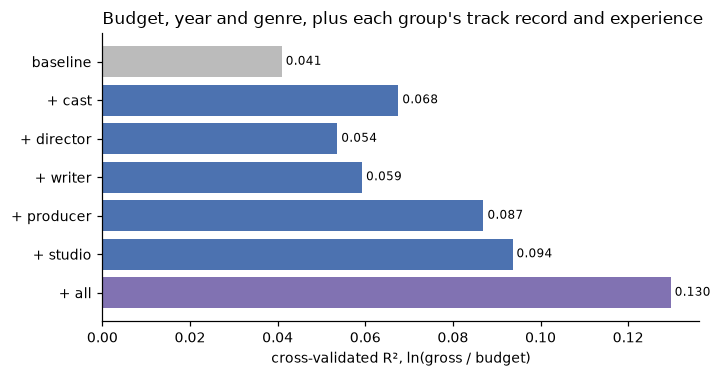

all network measures: R2 0.041 -> 0.130 (gain +0.089); shuffle p = 0.005 (the smallest possible with 200 shuffles is 0.005)


In [10]:
gen = d.genres.fillna("").str.get_dummies(sep=",")
gen = gen[[g for g in gen if gen[g].sum() >= 50]]
X = d[NF.columns].copy()
for c in NF.columns:
    if X[c].isna().any():
        X[c + "_missing"] = X[c].isna().astype(float)
        X[c] = X[c].fillna(d.log_mult.mean() if c.endswith("_track") else 0)

def cv_r2(Xm, y, seed):
    s = []
    for tr, te in KFold(5, shuffle=True, random_state=seed).split(Xm):
        m = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 25))).fit(Xm[tr], y[tr])
        s.append(r2_score(y[te], m.predict(Xm[te])))
    return float(np.mean(s))
def r2(frame, cols=None):
    y = frame.log_mult.values
    base = np.column_stack([frame.log_budget, frame.year, gen.loc[frame.index].values])
    Xm = base if cols is None else np.column_stack([base, X.loc[frame.index, cols].values])
    return float(np.mean([cv_r2(Xm, y, SEED + r) for r in range(10)]))

blocks = {"baseline": None}
for g in ["cast", "director", "writer", "producer", "studio"]:
    blocks[f"+ {g}"] = [c for c in X if c.startswith(g)]
blocks["+ all"] = list(X.columns)
R2 = pd.Series({k: r2(d, v) for k, v in blocks.items()})

rng = np.random.default_rng(SEED); y = d.log_mult.values
base = np.column_stack([d.log_budget, d.year, gen.values])
null = [cv_r2(np.column_stack([base, X.values[rng.permutation(len(y))]]), y, SEED) - cv_r2(base, y, SEED) for _ in range(200)]
gain = R2["+ all"] - R2["baseline"]
p_shuffle = (1 + sum(n >= gain for n in null)) / 201

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(R2.index[::-1], R2.values[::-1], color=["#8172b2"] + ["#4c72b0"] * 5 + ["#bbbbbb"])
for i, v in enumerate(R2.values[::-1]):
    ax.text(v, i, f" {v:.3f}", va="center", fontsize=8)
ax.set_xlabel("cross-validated R², ln(gross / budget)")
ax.set_title("Budget, year and genre, plus each group's track record and experience", loc="left")
plt.show()
print(f"all network measures: R2 {R2['baseline']:.3f} -> {R2['+ all']:.3f} (gain {gain:+.3f}); "
      f"shuffle p = {p_shuffle:.3f} (the smallest possible with 200 shuffles is {1 / 201:.3f})")

### Is it just sequels, horror or Blumhouse?

A hit's sequel shares its producers and studio, and cheap-horror specialists (Blumhouse, Jason Blum) post
high multiples year after year. Either could produce a track-record effect on its own. The sequel flag is
Wikidata's "follows" property, which misses some sequels and first films of a series.

In [11]:
seq = set()
with open(G.parent / "wd_follows.tsv") as fh:
    next(fh)
    seq = {line.split("\t")[0].strip('"') for line in fh}
blum = {"nm0089658"} | set(nodes.index[(nodes.type == "company") & nodes.names.fillna("").str.contains("Blumhouse")])
blum_films = set(edges.target[edges.source.isin(blum)])
is_seq, is_horror, is_blum = d.index.isin(seq), d.genres.fillna("").str.contains("Horror"), d.index.isin(blum_films)
rows = []
for label, mask in [("all films 1980+", np.ones(len(d), bool)), ("no sequels", ~is_seq), ("no horror", ~is_horror),
                    ("no Blumhouse or Jason Blum", ~is_blum), ("none of the three", ~is_seq & ~is_horror & ~is_blum)]:
    sub = d[mask]
    row = {"sample": label, "films": len(sub), "R2 baseline": r2(sub), "R2 + network": r2(sub, list(X.columns))}
    for g in ["studio", "producer", "director", "cast"]:
        s2 = sub.dropna(subset=[f"{g}_track"])
        row[f"{g} track rho"] = rank_partial(s2.log_mult.values, s2[f"{g}_track"].values, s2[["log_budget", "year"]].values)[0]
    rows.append(row)
pd.DataFrame(rows).round(3)

,sample,films,R2 baseline,R2 + network,studio track rho,producer track rho,director track rho,cast track rho
0,all films 1980+,6313,0.041,0.130,0.274,0.261,0.203,0.149
1,no sequels,5523,0.044,0.114,0.244,0.223,0.164,0.125
2,no horror,5510,0.045,0.119,0.236,0.234,0.183,0.145
3,no Blumhouse or Jason Blum,6238,0.040,0.119,0.253,0.240,0.193,0.144
4,none of the three,4871,0.049,0.109,0.213,0.205,0.154,0.129


### Do hit-makers keep making hits?

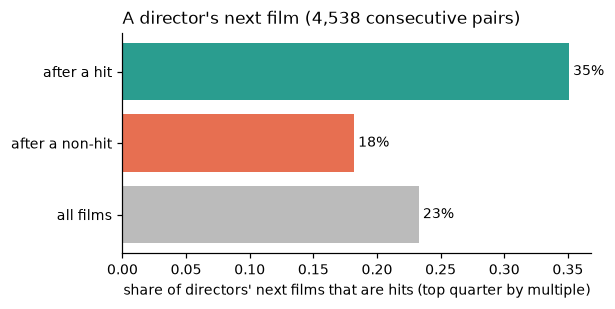

In [12]:
hit = cm.log_mult.quantile(0.75)
pairs = []
for dname, films in dir_films.items():
    fs = sorted((f for f in films if f in lm), key=lambda f: (yr[f], f))
    pairs += [(lm[a] >= hit, lm[b] >= hit) for a, b in zip(fs, fs[1:])]
pairs = np.array(pairs)
after = {"after a hit": pairs[pairs[:, 0], 1].mean(), "after a non-hit": pairs[~pairs[:, 0], 1].mean(),
         "all films": pairs[:, 1].mean()}
fig, ax = plt.subplots(figsize=(5.5, 2.6))
ax.barh(list(after)[::-1], list(after.values())[::-1], color=["#bbbbbb", "#e76f51", "#2a9d8f"])
for i, v in enumerate(list(after.values())[::-1]):
    ax.text(v, i, f" {v:.0%}", va="center")
ax.set_xlabel("share of directors' next films that are hits (top quarter by multiple)")
ax.set_title(f"A director's next film ({len(pairs):,} consecutive pairs)", loc="left")
plt.show()

These are raw shares, with no control for budget: a director who makes cheap films keeps making cheap
films, and cheap films have higher multiples. The track-record table above holds budget fixed.

### Do films that share people share results?

For each pair of clean films (1980 on) that share a director, writer or top-five actor, compare their
profit after removing what budget, year and genre explain. The null shuffles those residuals among films
released in the same year, keeping the pairs. People with more than 60 films are left out of the pairing,
since they would add thousands of near-random pairs.

In [13]:
dd = cm[cm.year >= 1980]
gg = dd.genres.fillna("").str.get_dummies(sep=","); gg = gg[[g for g in gg if gg[g].sum() >= 50]]
Xb = np.column_stack([np.ones(len(dd)), dd.log_budget, dd.year, gg.values])
resid = pd.Series(dd.log_mult.values - Xb @ np.linalg.lstsq(Xb, dd.log_mult.values, rcond=None)[0], index=dd.index)
shared = edges[edges.target.isin(dd.index) & (edges.role.isin(["director", "writer"]) | ((edges.role == "actor") & (edges.ordering <= 5)))]
pp = set()
for s, grp in shared.groupby("source"):
    fs = sorted(set(grp.target))
    if len(fs) <= 60:
        pp.update(combinations(fs, 2))
pp = np.array(sorted(pp))
obs = stats.pearsonr(resid.loc[pp[:, 0]].values, resid.loc[pp[:, 1]].values)[0]
rng = np.random.default_rng(SEED); yrs = dd.year.values; nullr = []
for _ in range(200):
    r = resid.values.copy()
    for yv in np.unique(yrs):
        i = np.where(yrs == yv)[0]; r[i] = r[rng.permutation(i)]
    rs = pd.Series(r, index=dd.index)
    nullr.append(stats.pearsonr(rs.loc[pp[:, 0]].values, rs.loc[pp[:, 1]].values)[0])
print(f"{len(pp):,} pairs: residual-profit correlation {obs:+.3f}; null {np.mean(nullr):+.3f} +- {np.std(nullr):.3f}, "
      f"largest of 200 shuffles {max(nullr):+.3f}")

175,997 pairs: residual-profit correlation +0.045; null +0.000 +- 0.002, largest of 200 shuffles +0.007


### Is the actor network more clustered than chance?

Projecting films onto actors makes every film a clique of its top-five cast, so a projection is clustered
by construction. The fair null keeps that: it rewires the film-actor graph itself, swapping actors between
films so that every actor keeps their number of films and every film its cast size, and then projects it.

In [14]:
bip = [(a, f) for a, f in zip(cast.source, cast.target)]
def project(edge_list):
    by_film = defaultdict(list)
    for a, f in edge_list:
        by_film[f].append(a)
    P = nx.Graph()
    for f, actors in by_film.items():
        P.add_edges_from(combinations(sorted(set(actors)), 2))
    return P

def rewire_bipartite(edge_list, seed, swaps_per_edge=10):
    rng = np.random.default_rng(seed)
    el = list(edge_list); have = set(el); n = len(el)
    for _ in range(swaps_per_edge * n):
        i, j = rng.integers(0, n, 2)
        (a1, f1), (a2, f2) = el[i], el[j]
        if a1 == a2 or f1 == f2 or (a1, f2) in have or (a2, f1) in have:
            continue
        have -= {(a1, f1), (a2, f2)}; have |= {(a1, f2), (a2, f1)}
        el[i], el[j] = (a1, f2), (a2, f1)
    return el

P_obs = project(bip)
c_obs, r_obs = nx.average_clustering(P_obs), nx.degree_assortativity_coefficient(P_obs)
null = [project(rewire_bipartite(bip, SEED + k)) for k in range(5)]
c_null = [nx.average_clustering(P) for P in null]
r_null = [nx.degree_assortativity_coefficient(P) for P in null]
print(f"actor projection (top-5 cast, clean films): clustering {c_obs:.3f} vs {np.mean(c_null):.3f} "
      f"(range {min(c_null):.3f} to {max(c_null):.3f}) after rewiring the film-actor graph; "
      f"degree assortativity {r_obs:+.3f} vs {np.mean(r_null):+.3f}")

actor projection (top-5 cast, clean films): clustering 0.753 vs 0.745 (range 0.745 to 0.745) after rewiring the film-actor graph; degree assortativity +0.160 vs -0.009


### What to take from it

Printed from the cells above, so it updates with the data.

In [15]:
top = T.iloc[0]
print(f"- Strongest single measure: {top.measure} (rho {top['rho net of budget and year']:+.2f} net of budget and year, "
      f"{int(top.films):,} films); {int((T.q < 0.05).sum())} of {len(T)} measures pass q < 0.05.")
print(f"- All network measures together: R2 {R2['baseline']:.3f} -> {R2['+ all']:.3f} over budget, year and genre "
      f"(shuffle p = {p_shuffle:.3f}).")
print(f"- A director's next film is a hit {after['after a hit']:.0%} of the time after a hit, "
      f"{after['after a non-hit']:.0%} after a non-hit.")
print(f"- Films sharing key people: residual-profit correlation {obs:+.3f} (null +-{np.std(nullr):.3f}).")
print(f"- Actor network clustering {c_obs:.3f} vs {np.mean(c_null):.3f} in the fair null.")

- Strongest single measure: studio track (rho +0.27 net of budget and year, 4,568 films); 11 of 11 measures pass q < 0.05.
- All network measures together: R2 0.041 -> 0.130 over budget, year and genre (shuffle p = 0.005).
- A director's next film is a hit 35% of the time after a hit, 18% after a non-hit.
- Films sharing key people: residual-profit correlation +0.045 (null +-0.002).
- Actor network clustering 0.753 vs 0.745 in the fair null.


These are associations, not causes. A studio's track record can stand for marketing budgets, distribution
deals, or how a studio reports its budgets. Company names are merged only by Wikidata ID, so a company whose
old name has no ID link (Fox Searchlight Pictures and Searchlight Pictures) still has its record split.

## Ideas to take further

- Communities in the actor or movie projection (Louvain or Infomap) and whether some communities make more
  money than others, against a degree-preserving null.
- Rolling networks: rebuild the projection from films up to year *t* and track who becomes central.
- Company networks: link companies that worked on the same films, and see which alliances make money.
- Assortativity: do high-multiple films share crews more than chance?